# Speculative decoding: English vs Hindi vs Urdu

**What this notebook does**
- Loads a **big model** (Qwen 3B, the checker) and a **small model** (Qwen 0.5B, the helper) onto your GPU
- Measures how much **one forward pass** of each model costs. This single number, `c`, decides whether the trick can win at all
- For every question, runs the big model two ways:
  - **normal:** big model alone, one token per pass
  - **speculative:** small model guesses `K` tokens, big model checks them all in one pass
- Sweeps `K` to find the best setting per language
- Checks the answers are identical and in the right language
- Saves the charts for your slides

**What we already know going in** (from the `rep_penalty = 1.0` run, 300 runs)
- `c ≈ 0.71` — a 0.5B forward pass costs **71%** of a 3B one, not the ~17% its size suggests
- **No K beat normal decoding.** Best was 0.91x at K=2
- **Hindi is not worse than English.** Only **Urdu** accepts fewer draft tokens
- English gets **4.4x more text per token** than Hindi (tokenizer tax)

This run repeats everything at `rep_penalty = 1.05` to check those hold — see section 7.

**The one equation to remember**

> `speedup ≈ tau / (1 + K·c)`

- `tau` = tokens produced per big-model pass. Normal decoding = 1.0. Higher = more guesses accepted
- `K` = how many tokens the helper guesses per round
- `c` = cost of a small-model pass as a fraction of a big-model pass
- So you win only when **`tau > 1 + K·c`**. Section 9 measures `c`, the rest measures `tau`

Run the cells top to bottom. The first run downloads ~7 GB of models.

> **Only load the models once per kernel.** Re-running section 5 loads a second
> copy, overflows the 8 GB card, and every timing after that is garbage.
> Restart the kernel instead.

## 1. Imports
- `torch`: runs models on the GPU
- `transformers`: loads Qwen + has speculative decoding built in
- `random`: shuffles the run order (see section 11)
- the rest: timing, maths, saving files

In [1]:
import csv, json, random, time
import statistics as st
from pathlib import Path

import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

## 2. Settings
- `TARGET`: the big model (checker)
- `DRAFT`: the small model (helper); must share the same tokenizer, which is why both are Qwen2.5
- `MAX_NEW`: max tokens per answer
- `LIMIT`: questions per language; `2` = quick test, `None` = all 10
- `K_SWEEP`: draft lengths to try
- `REPEATS`: how many times each measurement is taken. The median is reported, so one
  random slowdown cannot move a result
- If you get a VRAM warning in section 5, change `TARGET` to `"Qwen/Qwen2.5-1.5B-Instruct"`

In [2]:
TARGET  = "Qwen/Qwen2.5-3B-Instruct"
DRAFT   = "Qwen/Qwen2.5-0.5B-Instruct"
MAX_NEW = 128
LANGS   = ["en", "hi", "ur"]
LIMIT   = None           # None = all 10 questions (~35 min). Set to 2 for a ~4 min trial run.
K_SWEEP = [2, 4, 6, 8]   # HF's unpinned default behaves like K=20 (see section 6)
REPEATS = 2              # trials per measurement; median is reported
SEED    = 0              # fixes the shuffled run order, so the run is reproducible
REP_PENALTY = 1.05       # see section 7. 1.05 = Qwen's own setting; 1.0 = true argmax
OUTNAME = "results_rp105"   # folder for this run's output

# Works whether the kernel started in this folder or not.
HERE = Path.cwd() if (Path.cwd() / "prompts.json").exists() else Path(globals().get("__vsc_ipynb_file__", ".")).parent
assert (HERE / "prompts.json").exists(), f"prompts.json not found next to the notebook (looked in {HERE})"
OUT = HERE / OUTNAME
OUT.mkdir(exist_ok=True)

LANG_NAMES = {"en": "English", "hi": "Hindi", "ur": "Urdu"}
SYSTEM = "Answer in the same language as the question."
print("working in", HERE)

working in C:\Users\kashif\pro-lol\done\Academics\Year 3\NLP\CA-3


## 3. Language check
- Problem: you ask in Hindi, the model may answer in English, which would quietly corrupt the Hindi result
- Fix: count what share of the letters belong to the expected alphabet
  - English → Latin, Hindi → Devanagari, Urdu → Arabic script
- If under 70%, the answer is marked wrong-language and left out of the averages
- Note these models **code-switch**: a Hindi answer often contains English words in
  brackets, so the ratio is usually ~0.8–0.95 rather than 1.0

In [3]:
SCRIPTS = {
    "en": [(0x0041, 0x005A), (0x0061, 0x007A)],
    "hi": [(0x0900, 0x097F)],
    "ur": [(0x0600, 0x06FF), (0x0750, 0x077F), (0xFB50, 0xFDFF), (0xFE70, 0xFEFF)],
}
LANG_OK_THRESHOLD = 0.7

def script_ratio(text, lang):
    letters = [c for c in text if c.isalpha()]
    if not letters:
        return 0.0
    hit = sum(any(a <= ord(c) <= b for a, b in SCRIPTS[lang]) for c in letters)
    return hit / len(letters)

# quick sanity test: should print 1.0, 1.0, 0.0
print(script_ratio("Rain forms when", "en"),
      script_ratio("बारिश तब बनती है", "hi"),
      script_ratio("Rain forms when", "ur"))

1.0 1.0 0.0


## 4. Counting big-model passes
- A "hook" is a tiny function that runs every time the big model runs
- Each run = one expensive pass, so we count them
- **tau = tokens generated ÷ passes**
  - Normal decoding: tau = 1 (one token per pass)
  - Speculative: tau > 1 means the helper's guesses got accepted
- tau is the clearest proof the trick is working

**Also here: a GPU clock probe.** This exists because of a real failure. Partway through an
earlier sweep the laptop's ASUS power profile changed and the GPU silently dropped from
**2580 MHz to 930 MHz**. Nothing crashed; the timings just quietly became meaningless, and
it was only caught by noticing the numbers looked odd. Now every run records the clock it
ran at, so that failure is visible *in the data* instead of being invisible.

Note it is sampled **outside** the timed region, so the probe itself can never affect a
measurement. And note what it does *not* threaten: tau is a count ratio, so clock speed
cannot touch it. Only wall-clock numbers are at risk.

In [4]:
import subprocess

class PassCounter:
    def __init__(self, model):
        self.n = 0
        model.register_forward_hook(self._hook)
    def _hook(self, *_):
        self.n += 1

def gpu_clock_mhz():
    # Sampled OUTSIDE every timed region, so it cannot affect a measurement.
    try:
        out = subprocess.run(
            ["nvidia-smi", "--query-gpu=clocks.sm", "--format=csv,noheader,nounits"],
            capture_output=True, text=True, timeout=5).stdout.strip().splitlines()[0]
        return int(out)
    except Exception:
        return None

print("GPU clock right now:", gpu_clock_mhz(), "MHz")

GPU clock right now: 2250 MHz


## 5. Load the models onto the GPU
- `float16` = half precision, which halves memory so both fit in 8 GB
- `device_map="cuda"` puts them on the GPU (needs `accelerate`)
- VRAM check: if nearly full, Windows silently spills into normal RAM and the timings become garbage
- **Run this cell once.** If you need to reload, restart the kernel first

In [5]:
assert torch.cuda.is_available(), "CUDA not available - fix the GPU first."
GPU = torch.cuda.get_device_name(0)
print("GPU:", GPU)

def load(name):
    m = AutoModelForCausalLM.from_pretrained(name, dtype=torch.float16, device_map="cuda")
    m.eval()
    return m

tok = AutoTokenizer.from_pretrained(TARGET)
target = load(TARGET)
draft = load(DRAFT)
counter = PassCounter(target)

used = torch.cuda.memory_allocated() / 2**30
total = torch.cuda.get_device_properties(0).total_memory / 2**30
print(f"VRAM: {used:.1f} / {total:.1f} GB")
if used > 0.85 * total:
    print("WARNING: VRAM nearly full - switch TARGET to the 1.5B model.")

GPU: NVIDIA GeForce RTX 4060 Laptop GPU


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

VRAM: 6.7 / 8.0 GB


## 6. Pinning the draft strategy  ← the most important fix

Hugging Face does **not** leave `K` alone, and its defaults are not what you would guess.
In transformers 4.57:

| setting | default | what it means |
|---|---|---|
| `num_assistant_tokens` | **20** | guess 20 tokens per round |
| `num_assistant_tokens_schedule` | `"constant"` | do *not* adapt that 20 |
| `assistant_confidence_threshold` | **0.4** | but stop early if the helper is unsure |

Two problems with leaving this alone:

1. **20 is far too many.** At `c ≈ 1`, guessing 20 tokens to accept ~3 means ~17 wasted
   small-model passes per round. That alone sinks the speedup.
2. **The threshold moves while you run.** When scikit-learn is installed (it is, in your
   venv), `update_candidate_strategy` fits an ROC curve after every round and **writes the
   new threshold back onto `draft.generation_config`** — where it survives into the *next*
   `generate()` call, and the next prompt, and the next language.

Problem 2 is what quietly broke the first run: the same question gave
`tau 2.91 / 0.91x` early on and `tau 4.57 / 0.58x` later in the same kernel. Because the
languages ran in a fixed order (en, en, hi, hi, ur, ur), Urdu was measured with a threshold
tuned on English. **Language was confounded with run order.**

`set_draft_strategy` fixes it by rewriting all three settings before *every* call:
- `num_assistant_tokens = K` — the real lever
- `num_assistant_tokens_schedule = "constant"` — already the default, set for clarity
- `assistant_confidence_threshold = 0.0` — `0` is falsy, which switches off both the early
  exit (its check is `> 0`) and the ROC write-back (its check is truthiness). So `K` is
  genuinely fixed and nothing leaks between calls

In [6]:
def set_draft_strategy(k):
    # Must run before EVERY assisted generate(): transformers mutates
    # assistant_confidence_threshold in place and the change persists on
    # draft.generation_config across calls.
    gc = draft.generation_config
    gc.num_assistant_tokens = int(k)
    gc.num_assistant_tokens_schedule = "constant"
    gc.assistant_confidence_threshold = 0.0   # disables early exit + ROC write-back

# What HF would have used if we never touched it:
print("HF defaults ->",
      "num_assistant_tokens =", draft.generation_config.num_assistant_tokens,
      "| schedule =", draft.generation_config.num_assistant_tokens_schedule,
      "| confidence_threshold =", draft.generation_config.assistant_confidence_threshold)
set_draft_strategy(4)
print("after pinning ->",
      "num_assistant_tokens =", draft.generation_config.num_assistant_tokens,
      "| confidence_threshold =", draft.generation_config.assistant_confidence_threshold)

HF defaults -> num_assistant_tokens = 20 | schedule = constant | confidence_threshold = 0.4
after pinning -> num_assistant_tokens = 4 | confidence_threshold = 0.0


## 7. The two core functions
- `encode`: wraps the question in Qwen's chat format and turns it into token IDs
- `generate`: runs the big model, with or without the helper, and times it
  - **The whole speculative decoding trick is the single line `kwargs["assistant_model"] = draft`**; Hugging Face does the rest
  - `do_sample=False` = greedy, so both runs should give the **same** answer
  - `torch.cuda.synchronize()` makes the timer wait until the GPU has actually finished

### Why `REP_PENALTY` needs a decision

Qwen ships `repetition_penalty` **1.05** for the 3B and **1.1** for the 0.5B in their
`generation_config`. If you leave it alone, the two models are penalised by *different*
amounts, which is clearly wrong. So it has to be set explicitly for both. But to what?

| value | effect |
|---|---|
| `1.0` | true argmax — "greedy" means what it says |
| `1.05` | Qwen's intended setting for the target |

The first run used `1.0`. It gave the purest measurement, but the 3B model **fell into
repetition loops in Urdu** — one answer was literally *"یہ یہاں یہاں یہاں یہاں یہاں"*
("this here here here here here"). Repetition penalty exists to stop exactly that.

This matters beyond readability: the penalty changes the token distribution, so it changes
what the draft model predicts, so **it can change tau**. Running at `1.05` is therefore a
*robustness check*, not a cosmetic one. If the Urdu effect survives both settings, it is a
real property of the language. If it disappears, the effect was an artefact of the config
and you need to know that before presenting.

In [7]:
GREEDY = dict(do_sample=False, temperature=None, top_p=None, top_k=None)

def encode(prompt):
    msgs = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": prompt}]
    text = tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    return tok(text, return_tensors="pt").to("cuda")

@torch.inference_mode()
def generate(inputs, max_new, k=0):
    # k=0 -> normal decoding. k>0 -> speculative with K=k draft tokens.
    kwargs = dict(max_new_tokens=max_new, pad_token_id=tok.eos_token_id,
                  repetition_penalty=REP_PENALTY, **GREEDY)
    if k:
        set_draft_strategy(k)                  # re-pin before every call
        kwargs["assistant_model"] = draft      # <-- speculative decoding switched on
    counter.n = 0
    torch.cuda.synchronize(); t0 = time.perf_counter()
    out = target.generate(**inputs, **kwargs)
    torch.cuda.synchronize(); dt = time.perf_counter() - t0
    new_ids = out[0, inputs["input_ids"].shape[1]:].tolist()
    return new_ids, dt, counter.n

## 8. Warm-up
- The first GPU run is always slow (loading kernels), so we do one throwaway run of each kind and don't count it

In [8]:
warm = encode("Hello, how are you?")
generate(warm, 32, k=0)
generate(warm, 32, k=K_SWEEP[0])
print("warmed up")

A custom logits processor of type <class 'transformers.generation.logits_process.RepetitionPenaltyLogitsProcessor'> has been passed to `.generate()`, but it was also created in `.generate()`, given its parameterization. The custom <class 'transformers.generation.logits_process.RepetitionPenaltyLogitsProcessor'> will take precedence. Please check the docstring of <class 'transformers.generation.logits_process.RepetitionPenaltyLogitsProcessor'> to see related `.generate()` flags.


warmed up


## 9. How much does one forward pass cost?  ← the number that explains everything

Normal greedy decoding is exactly **one forward pass per token**, so "seconds per token"
for a model running alone *is* "seconds per forward pass".

We measure it for both models and take the ratio:

> `c = draft seconds-per-pass ÷ target seconds-per-pass`

- In theory a 0.5B model should be ~6x cheaper than a 3B model, so `c ≈ 0.17`
- In practice, at batch size 1 the GPU is nowhere near busy — the time goes on Python,
  kernel launches and memory traffic, which barely depend on model size. So `c` comes out
  **much closer to 1**
- Once you know `c`, you know the answer before running anything: you need
  **`tau > 1 + K·c`**. If `c ≈ 1` and `K = 4`, you need `tau > 5`, and the best English
  tau we ever saw was ~4.6

This is the honest explanation for a speedup below 1, and it is a *hardware and framework*
result, not a language result.

In [9]:
@torch.inference_mode()
def pass_cost(model, n=64):
    inputs = encode("Explain how rain forms.")
    for _ in range(2):   # warm up this model's kernels
        model.generate(**inputs, max_new_tokens=8, min_new_tokens=8,
                       pad_token_id=tok.eos_token_id,
                       repetition_penalty=REP_PENALTY, **GREEDY)
    torch.cuda.synchronize(); t0 = time.perf_counter()
    model.generate(**inputs, max_new_tokens=n, min_new_tokens=n,
                   pad_token_id=tok.eos_token_id,
                   repetition_penalty=REP_PENALTY, **GREEDY)
    torch.cuda.synchronize()
    return (time.perf_counter() - t0) / n

T_PASS = pass_cost(target)
D_PASS = pass_cost(draft)
C = D_PASS / T_PASS
counter.n = 0

print(f"target (3B):   {T_PASS*1e3:6.1f} ms per pass")
print(f"draft  (0.5B): {D_PASS*1e3:6.1f} ms per pass")
print(f"c = {C:.2f}   (a draft pass costs {C:.0%} of a target pass)")
print(f"\nSo a speedup needs tau > 1 + K*c:")
for k in K_SWEEP:
    print(f"   K={k}: need tau > {1 + k*C:.1f}")

target (3B):     34.6 ms per pass
draft  (0.5B):   23.1 ms per pass
c = 0.67   (a draft pass costs 67% of a target pass)

So a speedup needs tau > 1 + K*c:
   K=2: need tau > 2.3
   K=4: need tau > 3.7
   K=6: need tau > 5.0
   K=8: need tau > 6.3


## 10. Try ONE question and see it work
- Run this before the full sweep to understand what's happening
- Compare: time, passes, tau, and whether both answers are identical
- The speculative run makes **far fewer** big-model passes but can still take longer in
  wall-clock time. That gap is the whole story of this project

In [10]:
q = encode("Explain how rain forms.")
a_ids, a_t, a_pass = generate(q, MAX_NEW, k=0)
b_ids, b_t, b_pass = generate(q, MAX_NEW, k=4)

print(f"normal:       {len(a_ids):3d} tokens in {a_t:.2f}s, {a_pass:3d} big-model passes, tau {len(a_ids)/a_pass:.2f}")
print(f"speculative:  {len(b_ids):3d} tokens in {b_t:.2f}s, {b_pass:3d} big-model passes, tau {len(b_ids)/max(b_pass,1):.2f}  (K=4)")
print(f"speedup: {(len(b_ids)/b_t)/(len(a_ids)/a_t):.2f}x | identical answers: {a_ids == b_ids}")
print("\nAnswer:\n", tok.decode(a_ids, skip_special_tokens=True))

normal:       128 tokens in 4.44s, 128 big-model passes, tau 1.00
speculative:  128 tokens in 5.16s,  40 big-model passes, tau 3.20  (K=4)
speedup: 0.86x | identical answers: True

Answer:
 Rain forms through a process called condensation and evaporation, which are part of the water cycle. Here's a simplified explanation:

1. **Evaporation**: Water from oceans, lakes, rivers, and other bodies of water heats up by the sun and turns into vapor or steam. This process is called evaporation.

2. **Condensation**: As the warm air containing water vapor rises, it cools down. When it cools, the water vapor changes back into tiny droplets of liquid, forming clouds. This process is called condensation.

3. **Precipitation**: If the droplets combine and grow large enough,


## 11. Main sweep: every question, every K

Three things here are deliberate, and all three were missing from the first run:

1. **Every condition is built up front as a list, then shuffled** (fixed `SEED`, so it is
   reproducible). In the first run the order was always en → hi → ur, with the baseline
   always before the speculative run. If the laptop warms up and throttles partway through,
   a fixed order puts all of that drift onto whatever ran last — which was Urdu. Shuffling
   spreads it across every condition instead of faking a language effect.
2. **Each condition runs `REPEATS` times** and is later aggregated by **median**. The first
   run had one Urdu trial where *both* the normal and speculative runs collapsed together
   (9.7 and 3.1 tok/s) — a transient, not a language effect. A median ignores it; a mean
   does not.
3. **The baseline is a condition too** (`k=0`), measured in the same shuffled stream, so it
   gets the same treatment as everything else.

The first baseline answer for each question is kept as the **canonical** output: every other
run of that question is compared against it, which also double-checks that greedy decoding
really is deterministic.

In [11]:
prompts = json.loads((HERE / "prompts.json").read_text(encoding="utf-8"))

conditions = []
for lang in LANGS:
    for i in range(len(prompts[lang][:LIMIT])):
        conditions.append((lang, i, 0))          # 0 = baseline
        for k in K_SWEEP:
            conditions.append((lang, i, k))

rows, canonical, ids_by_row = [], {}, []
rng = random.Random(SEED)
total_runs = len(conditions) * REPEATS
done = 0
t_start = time.perf_counter()

for rep in range(REPEATS):
    order = conditions[:]
    rng.shuffle(order)                            # spread thermal drift across conditions
    for lang, i, k in order:
        inputs = encode(prompts[lang][i])
        ids, dt, passes = generate(inputs, MAX_NEW, k=k)
        key = (lang, i)
        if k == 0 and key not in canonical:
            canonical[key] = ids
        done += 1
        tau = len(ids) / max(passes, 1)
        ids_by_row.append(ids)
        rows.append(dict(
            repeat=rep, lang=lang, prompt_id=i, k=k,
            mode=("baseline" if k == 0 else f"spec_k{k}"),
            tokens=len(ids), sec=round(dt, 3), tps=round(len(ids)/dt, 2),
            passes=passes, tau=round(tau, 3),
            matches_baseline=None,        # resolved after the loop, see below
            sm_mhz=gpu_clock_mhz(),       # sampled outside the timed region
            wall=round(time.perf_counter() - t_start, 1),
        ))
        label = "baseline" if k == 0 else f"K={k}"
        print(f"[{done:3d}/{total_runs}] {lang} p{i} {label:>9s} | "
              f"{len(ids)/dt:6.1f} tok/s | {passes:4d} passes | tau {tau:.2f}")

# Resolve the identical-output check only now. The order is shuffled, so a
# speculative run can land before that question's first baseline; comparing
# inside the loop would score those as "not identical".
for r, ids in zip(rows, ids_by_row):
    r["matches_baseline"] = ids == canonical[(r["lang"], r["prompt_id"])]

print(f"\ndone in {(time.perf_counter()-t_start)/60:.1f} min")
print("all outputs identical to baseline:", all(r["matches_baseline"] for r in rows))

[  1/300] en p5       K=4 |   23.1 tok/s |   44 passes | tau 2.91


[  2/300] hi p0  baseline |   28.9 tok/s |  128 passes | tau 1.00


[  3/300] hi p0       K=6 |   14.7 tok/s |   50 passes | tau 2.56


[  4/300] ur p4       K=6 |   11.5 tok/s |   66 passes | tau 1.94


[  5/300] hi p9  baseline |   29.0 tok/s |  128 passes | tau 1.00


...

[296/300] en p9       K=8 |   13.3 tok/s |   35 passes | tau 3.23


[297/300] en p1  baseline |   25.7 tok/s |  128 passes | tau 1.00


[298/300] en p1       K=8 |   12.9 tok/s |   39 passes | tau 3.28


[299/300] en p5       K=8 |   14.0 tok/s |   35 passes | tau 3.66


[300/300] hi p8       K=8 |   16.7 tok/s |   30 passes | tau 4.27

done in 37.9 min
all outputs identical to baseline: False


## 12. Language check + the tokenizer tax

The canonical answer for each question gives us:
- `script_ratio` / `lang_ok`: is the answer actually in the asked language?
- `tokens_per_word` and `chars_per_token`: how much **text** you get per token

That second pair matters more than it looks. All three languages get the same 128-token
budget, but in the first run English produced **581 characters** and Hindi only **139** for
the same budget. Hindi and Urdu cost roughly 3–4x more tokens per word, so even at an
identical tok/s you receive 3–4x less writing. That is a separate penalty on top of the
acceptance-rate one, and it holds regardless of what happens to the speedup.

In [12]:
samples, meta = [], {}
for (lang, i), ids in canonical.items():
    text = tok.decode(ids, skip_special_tokens=True)
    sr = script_ratio(text, lang)
    meta[(lang, i)] = dict(
        lang_ok=sr >= LANG_OK_THRESHOLD,
        script_ratio=round(sr, 2),
        tokens_per_word=round(len(ids) / max(len(text.split()), 1), 2),
        chars_per_token=round(len(text) / max(len(ids), 1), 2),
    )
    samples.append(dict(lang=lang, prompt_id=i, prompt=prompts[lang][i], output=text, **meta[(lang, i)]))
samples.sort(key=lambda s: (LANGS.index(s["lang"]), s["prompt_id"]))

for r in rows:
    r.update(meta[(r["lang"], r["prompt_id"])])

for lang in LANGS:
    m = [v for (l, _), v in meta.items() if l == lang]
    if not m:
        continue
    chars = [s for s in samples if s["lang"] == lang]
    print(f"{LANG_NAMES[lang]:8s} right language {sum(x['lang_ok'] for x in m)}/{len(m)}"
          f" | tokens/word {st.median(x['tokens_per_word'] for x in m):.2f}"
          f" | chars/token {st.median(x['chars_per_token'] for x in m):.2f}"
          f" | median answer length {st.median(len(s['output']) for s in chars):.0f} chars")

English  right language 10/10 | tokens/word 1.19 | chars/token 5.04 | median answer length 614 chars
Hindi    right language 10/10 | tokens/word 4.66 | chars/token 1.06 | median answer length 136 chars
Urdu     right language 10/10 | tokens/word 3.12 | chars/token 1.44 | median answer length 184 chars


## 13. Summary per language
- Only right-language answers are counted
- **Median** over repeats, then median over questions — one bad trial cannot move it
- `baseline spread` shows the slowest and fastest normal run seen for that language. If
  that range is wide, the laptop was drifting and you should re-run on Turbo, plugged in
- `tau pooled` = *total* tokens ÷ *total* passes, which is the unbiased way to average a
  ratio (averaging per-question ratios is slightly biased)
- `predicted` is `tau_pooled / (1 + K·c)` from section 9. **If predicted ≈ observed, the
  overhead model is right and you can explain the whole result from one number**

### What to look for — and what the previous run already showed

The original hypothesis was *"the small drafter is weaker in Hindi **and** Urdu, so both
accept fewer guesses."* **That turned out to be half wrong.** At `rep_penalty = 1.0`:

| K | English | Hindi | Urdu |
|---|---|---|---|
| 2 | 2.19 | **2.23** | **1.98** |
| 4 | 2.72 | **2.84** | **2.35** |
| 6 | 3.01 | **3.14** | **2.54** |
| 8 | 3.16 | **3.37** | **2.58** |

Hindi matched or beat English at every K. Only Urdu was lower. Per-prompt, Urdu < Hindi in
**9–10 of 10** questions, while Hindi < English in only 3–4 of 10.

So the two questions for this run are:

1. **Does `ur < hi` survive at `rep_penalty = 1.05`?** If yes, the effect is a real property
   of the language, not of one decoding config. That is the claim the talk rests on.
2. **Does `hi ≈ en` still hold?** If Hindi stays level with English, the easy story
   ("non-English is worse") stays dead, and the interesting question becomes *why Urdu
   specifically* — most likely far less Urdu script than Devanagari in Qwen's pretraining.

Also watch `GPU clock` (should say *steady*) and `baseline spread` (should be tight, ~28–29,
not 18–29). Those two decide whether the **speedup** numbers are trustworthy. `tau` is a
count ratio and is trustworthy either way.

In [13]:
def summarise(rows):
    ok = [r for r in rows if r["lang_ok"]]
    summary = dict(gpu=GPU, target=TARGET, draft=DRAFT, max_new=MAX_NEW,
                   repeats=REPEATS, seed=SEED, k_sweep=K_SWEEP,
                   rep_penalty=REP_PENALTY,
                   target_ms_per_pass=round(T_PASS*1e3, 2),
                   draft_ms_per_pass=round(D_PASS*1e3, 2), c=round(C, 3), langs={})
    for lang in LANGS:
        lr = [r for r in ok if r["lang"] == lang]
        all_lang = [r for r in rows if r["lang"] == lang]
        if not lr or not all_lang:
            continue
        base = {}
        for p in sorted({r["prompt_id"] for r in lr}):
            b = [r["tps"] for r in lr if r["prompt_id"] == p and r["k"] == 0]
            if b:
                base[p] = st.median(b)
        if not base:
            continue
        drift = [r["tps"] for r in all_lang if r["k"] == 0]
        clocks = [r["sm_mhz"] for r in all_lang if r.get("sm_mhz")]
        e = dict(n_prompts=len(base),
                 sm_mhz_min=min(clocks) if clocks else None,
                 sm_mhz_max=max(clocks) if clocks else None,
                 sm_mhz_median=round(st.median(clocks)) if clocks else None,
                 sm_mhz_slow_runs=sum(1 for c in clocks if c < 2000),
                 lang_ok_rate=round(len({r['prompt_id'] for r in lr}) / len({r['prompt_id'] for r in all_lang}), 2),
                 base_tps=round(st.median(base.values()), 2),
                 baseline_tps_min=round(min(drift), 2), baseline_tps_max=round(max(drift), 2),
                 tokens_per_word=round(st.median(r["tokens_per_word"] for r in lr if r["k"] == 0), 2),
                 chars_per_token=round(st.median(r["chars_per_token"] for r in lr if r["k"] == 0), 2),
                 by_k={})
        for k in K_SWEEP:
            kr = [r for r in lr if r["k"] == k]
            if not kr:
                continue
            speedups, taus = [], []
            for p in base:
                pr = [r for r in kr if r["prompt_id"] == p]
                if pr:
                    speedups.append(st.median(r["tps"] for r in pr) / base[p])
                    taus.append(st.median(r["tau"] for r in pr))
            if not speedups:
                continue
            tau_pooled = sum(r["tokens"] for r in kr) / max(sum(r["passes"] for r in kr), 1)
            e["by_k"][str(k)] = dict(
                spec_tps=round(st.median(r["tps"] for r in kr), 2),
                speedup=round(st.median(speedups), 3),
                speedup_sd=round(st.pstdev(speedups), 3) if len(speedups) > 1 else 0.0,
                tau=round(st.median(taus), 3), tau_pooled=round(tau_pooled, 3),
                predicted_speedup=round(tau_pooled / (1 + k*C), 3),
                identical_rate=round(sum(bool(r["matches_baseline"]) for r in kr) / len(kr), 2))
        if e["by_k"]:
            best = max(e["by_k"], key=lambda k: e["by_k"][k]["speedup"])
            e["best_k"], e["best_speedup"] = int(best), e["by_k"][best]["speedup"]
        summary["langs"][lang] = e
    return summary

summary = summarise(rows)

print(f"c = {summary['c']:.2f}  (target {summary['target_ms_per_pass']:.1f} ms/pass,"
      f" draft {summary['draft_ms_per_pass']:.1f} ms/pass)   rep_penalty = {REP_PENALTY}")
for lang, s in summary["langs"].items():
    print(f"\n{LANG_NAMES[lang]}  (n={s['n_prompts']} questions, right language {s['lang_ok_rate']:.0%})")
    print(f"  normal {s['base_tps']:.1f} tok/s  (baseline spread {s['baseline_tps_min']:.1f}-{s['baseline_tps_max']:.1f})")
    if s.get("sm_mhz_median"):
        bad = s["sm_mhz_slow_runs"]
        flag = f"   <-- {bad} run(s) below 2000 MHz, their timings are suspect" if bad else "   (steady)"
        print(f"  GPU clock {s['sm_mhz_min']}-{s['sm_mhz_max']} MHz, median {s['sm_mhz_median']}{flag}")
    print(f"  {'K':>3s} {'spec tok/s':>11s} {'speedup':>8s} {'tau':>6s} {'tau pooled':>11s} {'predicted':>10s} {'identical':>10s}")
    for k, d in s["by_k"].items():
        print(f"  {k:>3s} {d['spec_tps']:>11.1f} {d['speedup']:>7.2f}x {d['tau']:>6.2f}"
              f" {d['tau_pooled']:>11.2f} {d['predicted_speedup']:>9.2f}x {d['identical_rate']:>9.0%}")
    if "best_k" in s:
        tail = "" if s["best_speedup"] > 1 else "   (still slower than normal decoding)"
        print(f"  best: K={s['best_k']} at {s['best_speedup']:.2f}x{tail}")

wins = [s["best_speedup"] for s in summary["langs"].values() if "best_speedup" in s]
if wins and max(wins) <= 1:
    print(f"\nNo K beat normal decoding (best {max(wins):.2f}x). With c = {summary['c']:.2f},"
          f" a win needs tau > 1 + K*c, and the measured tau never gets there."
          f"\nThat is the honest finding: on this GPU + HF, per-call overhead dominates."
          f" The language effect on tau is a separate, independent result.")

c = 0.67  (target 34.6 ms/pass, draft 23.1 ms/pass)   rep_penalty = 1.05

English  (n=10 questions, right language 100%)
  normal 26.8 tok/s  (baseline spread 25.7-28.8)
  GPU clock 2115-2595 MHz, median 2580   (steady)
    K  spec tok/s  speedup    tau  tau pooled  predicted  identical
    2        23.8    0.92x   2.19        2.16      0.92x       80%
    4        18.4    0.69x   2.74        2.64      0.72x       70%
    6        16.7    0.63x   3.15        2.99      0.60x       80%
    8        13.0    0.50x   3.28        3.11      0.49x       70%
  best: K=2 at 0.92x   (still slower than normal decoding)

Hindi  (n=10 questions, right language 100%)
  normal 27.1 tok/s  (baseline spread 25.6-29.0)
  GPU clock 2340-2580 MHz, median 2580   (steady)
    K  spec tok/s  speedup    tau  tau pooled  predicted  identical
    2        22.2    0.85x   2.13        2.16      0.92x       90%
    4        19.8    0.76x   2.73        2.71      0.74x       90%
    6        15.8    0.58x   2.94     

## 14. Charts for the slides
- **`sweep.png`** (left: speedup vs K, right: tau vs K) is your Example slide. The right
  panel is the real finding: the three lines are separated by language, English on top
- **`speedup.png`** is a simpler one-bar-per-language version for the README
- Dashed line at 1.0 = "no speedup"

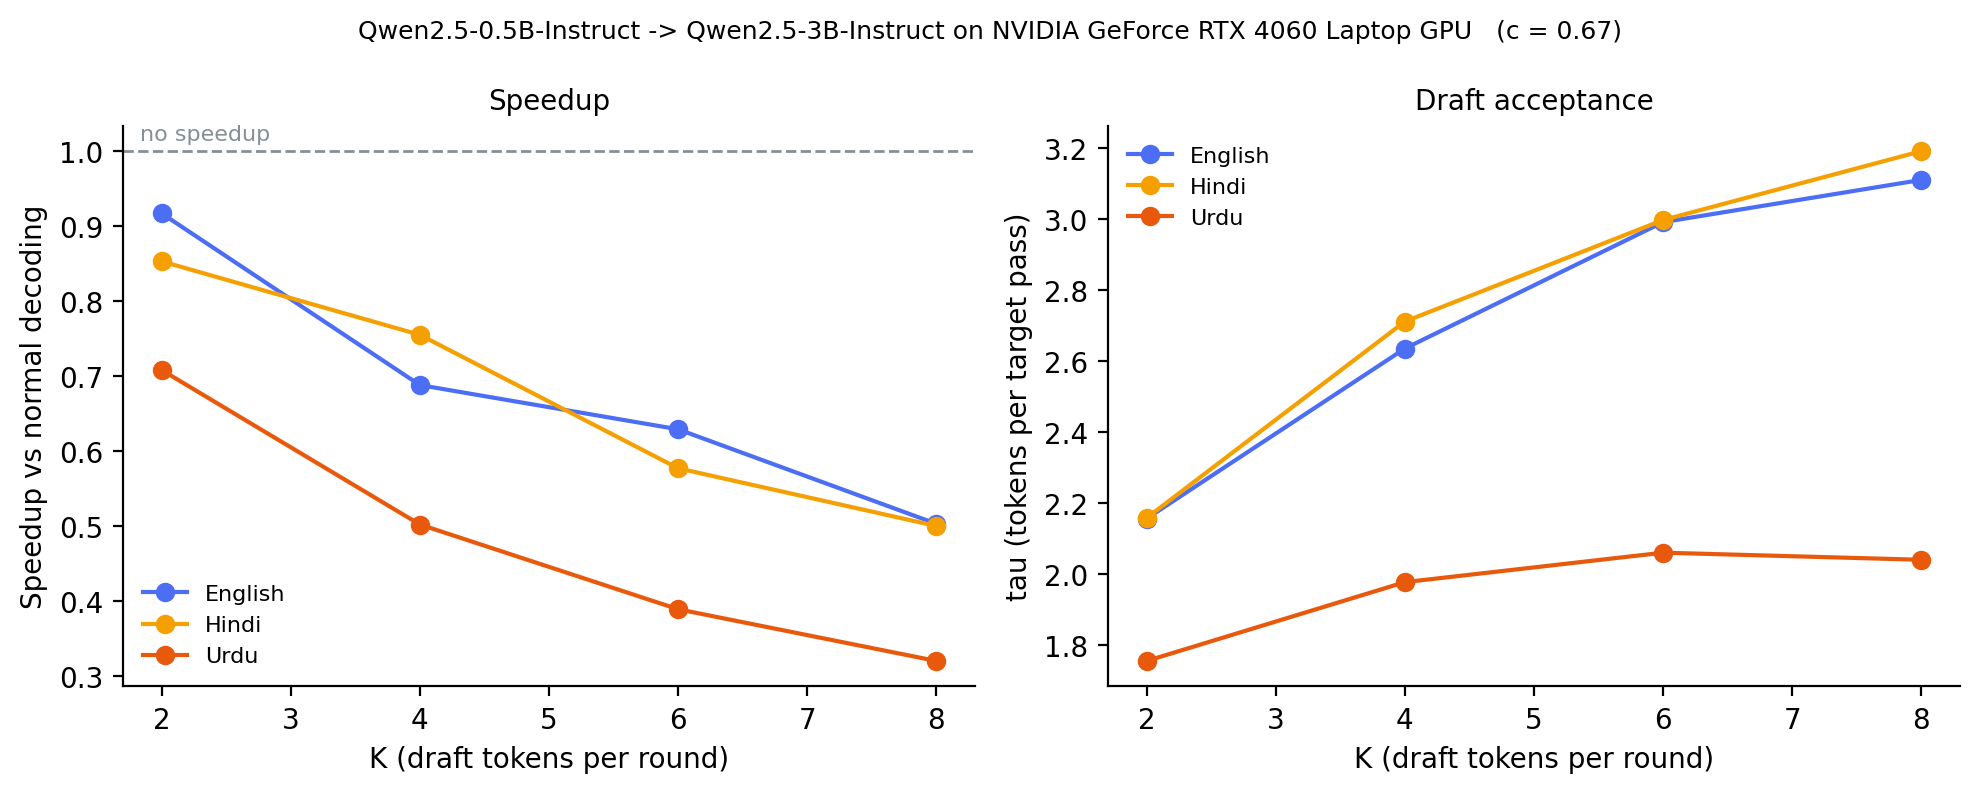

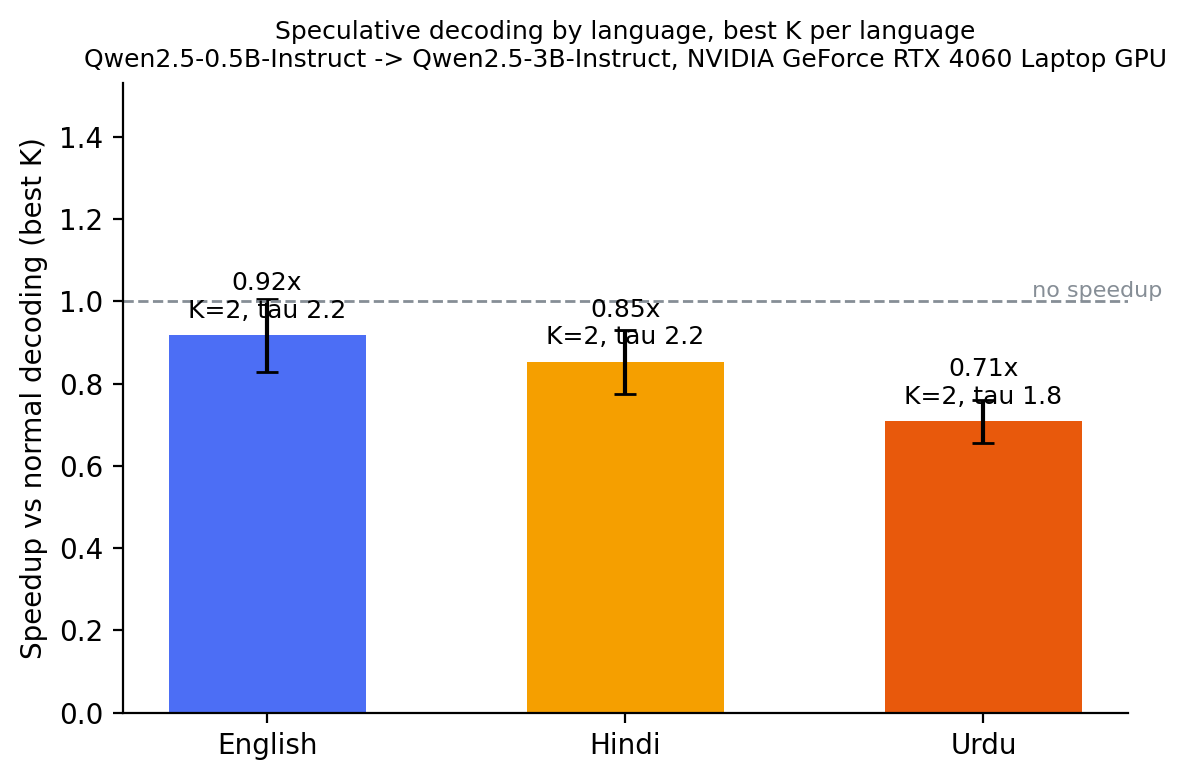

In [14]:
import matplotlib.pyplot as plt

langs = [l for l in LANGS if l in summary["langs"]]
colors = {"en": "#4C6EF5", "hi": "#F59F00", "ur": "#E8590C"}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4), dpi=200)
for l in langs:
    by_k = summary["langs"][l]["by_k"]
    ks = sorted(int(k) for k in by_k)
    ax1.plot(ks, [by_k[str(k)]["speedup"] for k in ks], "o-", color=colors[l], label=LANG_NAMES[l])
    ax2.plot(ks, [by_k[str(k)]["tau_pooled"] for k in ks], "o-", color=colors[l], label=LANG_NAMES[l])
ax1.axhline(1.0, color="#868E96", lw=1, ls="--")
ax1.text(0.02, 1.01, "no speedup", transform=ax1.get_yaxis_transform(), fontsize=8, color="#868E96", va="bottom")
ax1.set_xlabel("K (draft tokens per round)"); ax1.set_ylabel("Speedup vs normal decoding")
ax1.set_title("Speedup", fontsize=10)
ax2.set_xlabel("K (draft tokens per round)"); ax2.set_ylabel("tau (tokens per target pass)")
ax2.set_title("Draft acceptance", fontsize=10)
for ax in (ax1, ax2):
    ax.legend(fontsize=8, frameon=False)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
fig.suptitle(f"{DRAFT.split('/')[-1]} -> {TARGET.split('/')[-1]} on {GPU}   (c = {summary['c']:.2f})", fontsize=9)
fig.tight_layout(); fig.savefig(OUT / "sweep.png"); plt.show()

have = [l for l in langs if "best_k" in summary["langs"][l]]
vals = [summary["langs"][l]["best_speedup"] for l in have]
bks  = [summary["langs"][l]["best_k"] for l in have]
sds  = [summary["langs"][l]["by_k"][str(b)]["speedup_sd"] for l, b in zip(have, bks)]
taus = [summary["langs"][l]["by_k"][str(b)]["tau_pooled"] for l, b in zip(have, bks)]

fig, ax = plt.subplots(figsize=(6, 4), dpi=200)
bars = ax.bar([LANG_NAMES[l] for l in have], vals, yerr=sds, capsize=4,
              color=[colors[l] for l in have], width=0.55)
ax.axhline(1.0, color="#868E96", lw=1, ls="--")
ax.text(len(have)-0.5, 1.0, " no speedup", va="bottom", ha="right", fontsize=8, color="#868E96")
for b, v, t, bk in zip(bars, vals, taus, bks):
    ax.text(b.get_x()+b.get_width()/2, v+0.03, f"{v:.2f}x\nK={bk}, tau {t:.1f}", ha="center", va="bottom", fontsize=9)
ax.set_ylabel("Speedup vs normal decoding (best K)")
ax.set_ylim(0, max(max(vals)*1.45+0.2, 1.15))
ax.set_title(f"Speculative decoding by language, best K per language\n{DRAFT.split('/')[-1]} -> {TARGET.split('/')[-1]}, {GPU}", fontsize=9)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
fig.tight_layout(); fig.savefig(OUT / "speedup.png"); plt.show()

## 15. Save everything
- `raw.csv`: every single trial, with its repeat number and wall-clock time
- `summary.json`: the per-language, per-K table plus `c`
- `outputs.json`: the actual answers; **open this and eyeball the Hindi/Urdu ones**
  (expect short, partly code-switched, sometimes plain wrong answers — report that honestly)

In [15]:
with open(OUT / "raw.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.DictWriter(f, fieldnames=rows[0].keys()); w.writeheader(); w.writerows(rows)
(OUT / "summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
(OUT / "outputs.json").write_text(json.dumps(samples, ensure_ascii=False, indent=2), encoding="utf-8")
print("Saved to", OUT)

Saved to C:\Users\kashif\pro-lol\done\Academics\Year 3\NLP\CA-3\results_rp105
